# Honeypot Ethics Review - Dataset Analysis

Unified dataset `honeypot_ethics_dataset.csv` (v3.1): **239 entries** = 38 scientific honeypot papers + 201 open-source honeypot tools (grey literature), 49 columns.

**What changed since the version reviewed in Meeting 12 (Nov 10, 2026)**
- Dataset v3 aligns every categorical value with the final open coding of the PDF papers and tool documentation (consent, researcher responsibility, containment, data sharing, deployment, minimization, retention).
- Consent model uses the final rule (consent judged only on what is obtained from attackers; no "Mixed"): 37 None, 1 Implicit (HoneySat banner). The old figure showed 68% because "Implicit" was assigned to most papers.
- **Data sensitivity** now follows a deployment-independent rubric (Meeting 12: "it doesn't matter whether it is deployed live or not"), and **attacker behaviour is reported separately** from sensitivity.
- **Documentation quality -> documentation quantity**, measured from the harvested README / wiki / docs / external text (one long README can be Extensive).
- "Irrelevant" and "Not Found" platforms are combined.
- The ethics governance figure covers 9 dimensions and counts partial minimization.

In [1]:
# Setup: libraries, paper style, palette
import os, re, warnings
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

SAVE_FIGS = False          # True -> write figures/<name>.pdf and .png (figures/ is git-ignored)
FIG_DIR = 'figures'
COL_W, FULL_W = 3.4, 7.0   # USENIX single-column and full-width figure widths (inches)

# Validated two-series palette (passes colorblind and contrast checks)
SCI, TOOL = '#2a78d6', '#eb6834'          # Scientific papers, Open-source tools
INK, MUTED, GRID = '#1f1f1f', '#6b6b6b', '#e6e6e6'
SRC_COLORS = {'Scientific': SCI, 'Non-Scientific': TOOL}
SRC_LABELS = {'Scientific': 'Scientific papers', 'Non-Scientific': 'Open-source tools'}

mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'Nimbus Roman', 'DejaVu Serif'],
    'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'legend.fontsize': 7.5, 'legend.frameon': False, 'figure.dpi': 150, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.grid': True, 'axes.grid.axis': 'x', 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def savefig(fig, name):
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in ('pdf', 'png'):
            fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'), bbox_inches='tight')

def parse_stars(v):
    s = str(v).strip().lower().replace(',', '')
    if s in ('', 'n/a', 'na', '-', 'none', 'nan'): return np.nan
    try:
        return float(s[:-1]) * 1000 if s.endswith('k') else float(s)
    except ValueError:
        return np.nan

def pct(mask):
    return 100 * mask.mean()

def top_legend(fig):
    # one legend above multi-panel figures, so it never covers bars
    h = [mpl.patches.Patch(color=SRC_COLORS[k], label=SRC_LABELS[k]) for k in ['Scientific', 'Non-Scientific']]
    fig.legend(handles=h, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=[0, 0, 1, 0.9])

def grouped_barh(ax, table, order=None, xlabel='Entries (%)', percent=True, label_fmt='{:.0f}%'):
    # table: index = categories, columns = source types, values = counts or %
    order = order or list(table.index)
    table = table.reindex(order).fillna(0)
    y = np.arange(len(order)); h = 0.38
    for k, src in enumerate(['Scientific', 'Non-Scientific']):
        if src not in table: continue
        vals = table[src].values
        bars = ax.barh(y + (k - 0.5) * h, vals, height=h - 0.04, color=SRC_COLORS[src], label=SRC_LABELS[src])
        for b, v in zip(bars, vals):
            ax.text(b.get_width() + (1 if percent else 0.5), b.get_y() + b.get_height() / 2,
                    label_fmt.format(v), va='center', fontsize=6.5, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis(); ax.set_xlabel(xlabel)
    if percent: ax.set_xlim(0, 110)
    return ax
print('Ready.')

Ready.


In [2]:
# Load the dataset and apply display-only label tidying
df = pd.read_csv('../dataset/honeypot_ethics_dataset.csv', low_memory=False)
for c in df.columns:
    if df[c].dtype == object:
        df[c] = df[c].str.strip()
ncols = df.shape[1]
df['consent_model'] = df['consent_model'].fillna('None')
df['deception_framing'] = df['deception_framing'].replace({'Ethical Discussion': 'Ethical discussion'})
df['platform'] = df['platform'].replace({'Irrelevant': 'Not found / N/A', 'Not Found': 'Not found / N/A'})   # Meeting 12
df['doc_level'] = df['doc_level'].fillna('None')
df['domain_group'] = df['domain'].replace({'Industrial IoT (IIoT)': 'IoT / IIoT', 'IoT': 'IoT / IIoT'})

sci  = df[df['source_type'] == 'Scientific'].copy()
nons = df[df['source_type'] == 'Non-Scientific'].copy()
N = {'Scientific': len(sci), 'Non-Scientific': len(nons)}
print(f"Entries: {len(df)} | Scientific papers: {len(sci)} | Open-source tools: {len(nons)} | Columns: {ncols}")

Entries: 239 | Scientific papers: 38 | Open-source tools: 201 | Columns: 49


## 1. Composition: domain and interaction level

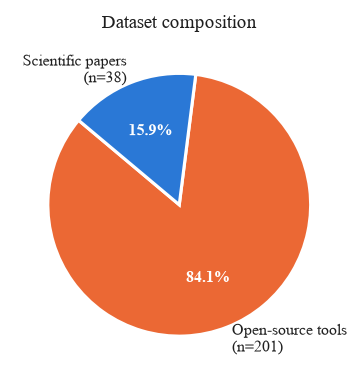

source_type
Non-Scientific    201
Scientific         38


In [3]:
# Overall composition (pie kept from the original notebook)
counts = df['source_type'].value_counts().reindex(['Non-Scientific', 'Scientific'])
fig, ax = plt.subplots(figsize=(COL_W, 2.6))
w, t_, a_ = ax.pie(counts, labels=[f"{SRC_LABELS[k]}\n(n={v})" for k, v in counts.items()], autopct='%1.1f%%',
                   colors=[SRC_COLORS[k] for k in counts.index], startangle=140,
                   wedgeprops=dict(edgecolor='white', linewidth=1.5), textprops=dict(fontsize=7.5))
for a in a_: a.set_color('white'); a.set_fontweight('bold')
ax.set_title('Dataset composition'); fig.tight_layout(); savefig(fig, 'composition'); plt.show()
print(counts.to_string())

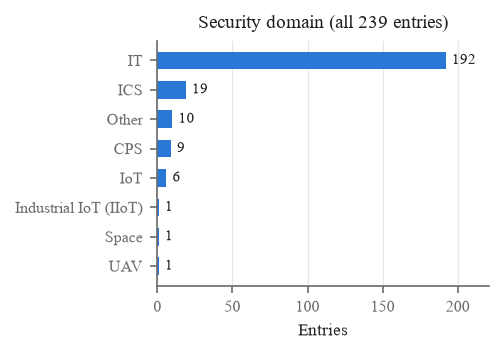

domain
IT                       192
ICS                       19
Other                     10
CPS                        9
IoT                        6
Industrial IoT (IIoT)      1
Space                      1
UAV                        1


In [4]:
# Security domain distribution (all 239 entries)
dc = df['domain'].value_counts()
fig, ax = plt.subplots(figsize=(COL_W, 2.4))
b = ax.barh(dc.index, dc.values, color=SCI, height=0.6); ax.invert_yaxis()
ax.bar_label(b, padding=3, fontsize=7); ax.set_xlim(0, dc.max() * 1.15); ax.set_xlabel('Entries')
ax.set_title(f'Security domain (all {len(df)} entries)'); fig.tight_layout(); savefig(fig, 'domain_all'); plt.show()
print(dc.to_string())

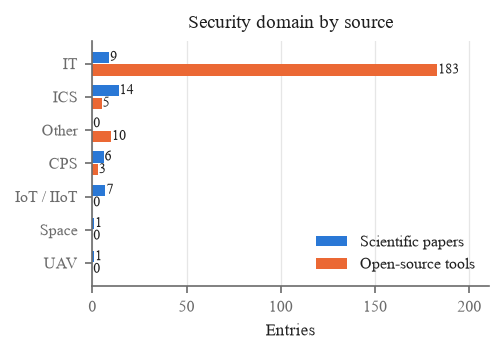

source_type   Non-Scientific  Scientific
domain_group                            
IT                       183           9
ICS                        5          14
Other                     10           0
CPS                        3           6
IoT / IIoT                 0           7
Space                      0           1
UAV                        0           1


In [5]:
# Domain by source type (counts)
order = df['domain_group'].value_counts().index.tolist()
t = df.groupby(['domain_group', 'source_type']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(COL_W, 2.4))
grouped_barh(ax, t, order, xlabel='Entries', percent=False, label_fmt='{:.0f}')
ax.set_xlim(0, t.values.max() * 1.15); ax.legend(loc='lower right')
ax.set_title('Security domain by source'); fig.tight_layout(); savefig(fig, 'domain_by_source'); plt.show()
print(t.reindex(order).to_string())

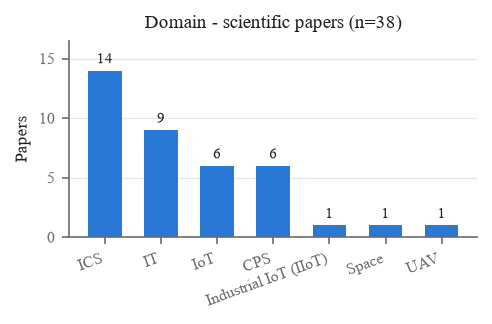

domain
ICS                      14
IT                        9
IoT                       6
CPS                       6
Industrial IoT (IIoT)     1
Space                     1
UAV                       1


In [6]:
# Domain distribution - scientific papers only
sd = sci['domain'].value_counts()
fig, ax = plt.subplots(figsize=(COL_W, 2.2))
b = ax.bar(sd.index, sd.values, color=SCI, width=0.6); ax.bar_label(b, padding=2, fontsize=7)
ax.grid(axis='y'); ax.grid(axis='x', visible=False); ax.set_ylabel('Papers'); ax.set_ylim(0, sd.max() * 1.18)
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
ax.set_title(f'Domain - scientific papers (n={len(sci)})'); fig.tight_layout(); savefig(fig, 'domain_scientific'); plt.show()
print(sd.to_string())

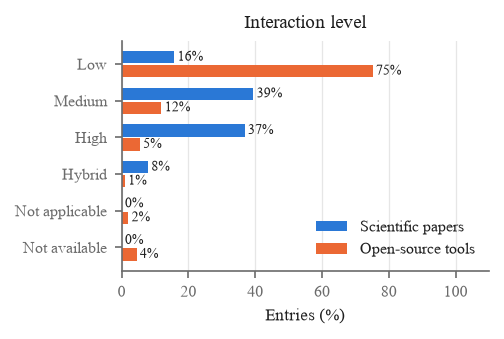

source_type        Non-Scientific  Scientific
interaction_level                            
Low                           151           6
Medium                         24          15
High                           11          14
Hybrid                          2           3
Not applicable                  4           0
Not available                   9           0


In [7]:
# Interaction level by source type (% of each source); now includes Hybrid and Not applicable
order = ['Low', 'Medium', 'High', 'Hybrid', 'Not applicable', 'Not available']
t = df.groupby(['interaction_level', 'source_type']).size().unstack(fill_value=0)
tp = t.div(pd.Series(N), axis=1) * 100
fig, ax = plt.subplots(figsize=(COL_W, 2.3))
grouped_barh(ax, tp, [o for o in order if o in tp.index])
ax.legend(loc='lower right'); ax.set_title('Interaction level'); fig.tight_layout(); savefig(fig, 'interaction_level'); plt.show()
print(t.reindex([o for o in order if o in t.index]).to_string())

## 2. Ethics governance discussion rate - PAPER FIG 1

The figure discussed in Meeting 12, corrected and extended. A dimension counts as discussed when the paper or tool documentation states it:
IRB approval; consent (Explicit or Implicit); data minimization (including Partial); retention policy; jurisdiction / legal; ethical discussion of deception; explicit researcher responsibility; documented containment (technical isolation, passive-only, or partial); data-sharing statement (any statement, including "on request").

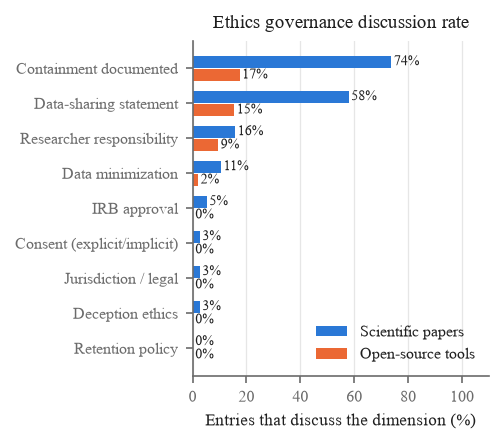

                             Scientific  Non-Scientific
Containment documented             73.7            17.4
Data-sharing statement             57.9            15.4
Researcher responsibility          15.8             9.5
Data minimization                  10.5             2.0
IRB approval                        5.3             0.0
Consent (explicit/implicit)         2.6             0.0
Jurisdiction / legal                2.6             0.0
Deception ethics                    2.6             0.0
Retention policy                    0.0             0.0


In [8]:
def documented(s, none_values):
    return ~s.fillna('').str.strip().str.lower().isin([v.lower() for v in none_values] + [''])

DIMS = {
    'IRB approval':              lambda d: d['irb_mentioned'].eq('Yes'),
    'Consent (explicit/implicit)': lambda d: d['consent_model'].isin(['Explicit', 'Implicit']),
    'Data minimization':         lambda d: d['data_minimization'].str.startswith('Yes', na=False),
    'Retention policy':          lambda d: documented(d['data_retention_policy'], ['Not discussed', 'Not documented', 'Not available']),
    'Jurisdiction / legal':      lambda d: documented(d['jurisdiction_legal'], ['Not discussed', 'Not documented', 'Not available']),
    'Deception ethics':          lambda d: d['deception_framing'].eq('Ethical discussion'),
    'Researcher responsibility': lambda d: d['researcher_responsibility'].eq('Explicit'),
    'Containment documented':    lambda d: ~d['containment_measures'].fillna('not documented').str.lower().str.startswith(('not documented', 'not applicable', 'not available')),
    'Data-sharing statement':    lambda d: ~d['data_sharing'].fillna('none mentioned').str.lower().str.startswith(('none mentioned', 'not available')),
}
gov = pd.DataFrame({src: {k: pct(f(sub)) for k, f in DIMS.items()} for src, sub in [('Scientific', sci), ('Non-Scientific', nons)]})
order = gov.mean(axis=1).sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(COL_W, 3.0))
grouped_barh(ax, gov, order, xlabel='Entries that discuss the dimension (%)')
ax.legend(loc='lower right'); ax.set_title('Ethics governance discussion rate')
fig.tight_layout(); savefig(fig, 'paper_fig1_governance_rate'); plt.show()
print(gov.reindex(order).round(1).to_string())

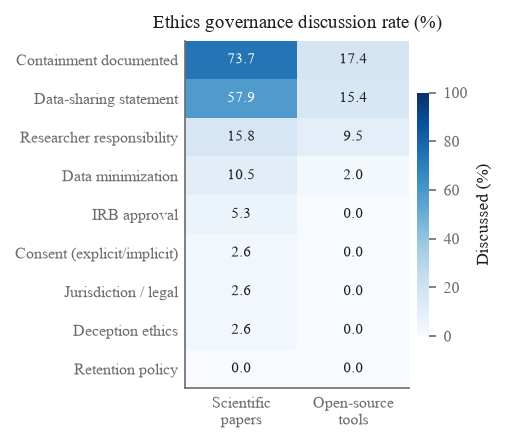

In [9]:
# Same data as a compact heatmap (the Meeting 12 layout), single-hue sequential scale
fig, ax = plt.subplots(figsize=(COL_W, 3.0))
g = gov.reindex(order).rename(columns=SRC_LABELS)
im = ax.imshow(g.values, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(g.shape[1])); ax.set_xticklabels([c.replace(' ', '\n', 1) for c in g.columns]); ax.set_yticks(range(g.shape[0])); ax.set_yticklabels(g.index)
ax.grid(False); ax.tick_params(length=0)
for (i, j), v in np.ndenumerate(g.values):
    ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=7, color='white' if v > 55 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03); cb.set_label('Discussed (%)'); cb.outline.set_visible(False)
ax.set_title('Ethics governance discussion rate (%)'); fig.tight_layout(); savefig(fig, 'governance_heatmap'); plt.show()

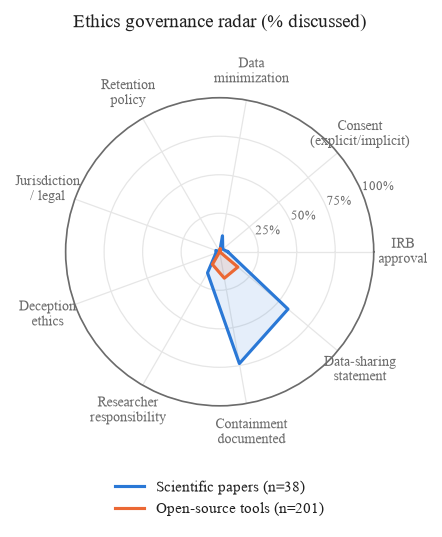

In [10]:
# Ethics governance radar (kept from the original notebook), now 9 dimensions
labels = [k.replace(' ', '\n', 1) for k in DIMS]
ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(COL_W, 3.6), subplot_kw=dict(polar=True))
for src, sub in [('Scientific', sci), ('Non-Scientific', nons)]:
    v = [gov.loc[k, src] for k in DIMS]; v += v[:1]
    ax.plot(ang, v, color=SRC_COLORS[src], lw=1.5, label=f"{SRC_LABELS[src]} (n={len(sub)})"); ax.fill(ang, v, color=SRC_COLORS[src], alpha=0.12)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=6.5); ax.set_ylim(0, 100)
ax.set_yticks([25, 50, 75, 100]); ax.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=6, color=MUTED)
ax.grid(color=GRID); ax.set_title('Ethics governance radar (% discussed)', pad=14)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=7)
fig.tight_layout(); savefig(fig, 'governance_radar'); plt.show()

## 3. Consent model (corrected)

Consent is judged only on what is obtained from attackers. Internet deployment with no notice is **None**; a login warning banner is **Implicit** (HoneySat). No entry obtains explicit consent, which is expected for honeypots and is why IRB oversight and data protection carry the weight.

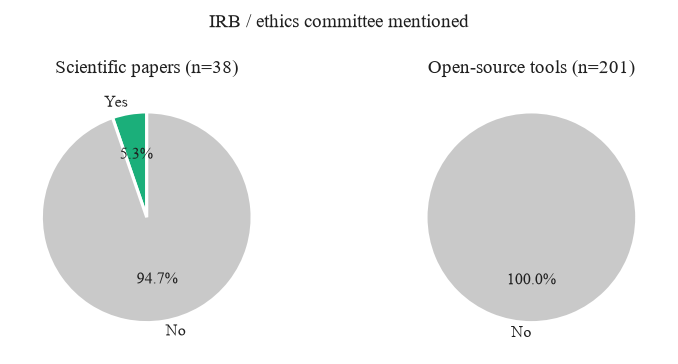

source_type    Non-Scientific  Scientific
irb_mentioned                            
No                        201          36
Yes                         0           2


In [11]:
# IRB mention rate (pies kept from the original notebook)
IRB_COL = {'Yes': '#1baf7a', 'No': '#c9c9c9'}
fig, axes = plt.subplots(1, 2, figsize=(FULL_W * 0.75, 2.4))
for ax, src in zip(axes, ['Scientific', 'Non-Scientific']):
    s_ = df[df['source_type'] == src]['irb_mentioned'].value_counts().reindex(['Yes', 'No']).dropna()
    s_ = s_[s_ > 0]
    ax.pie(s_, labels=s_.index, autopct='%1.1f%%', colors=[IRB_COL[k] for k in s_.index], startangle=90,
           wedgeprops=dict(edgecolor='white', linewidth=1.5), textprops=dict(fontsize=7.5))
    ax.set_title(f"{SRC_LABELS[src]} (n={N[src]})")
fig.suptitle('IRB / ethics committee mentioned', fontsize=9); fig.tight_layout(); savefig(fig, 'irb_rate'); plt.show()
print(df.groupby(['irb_mentioned', 'source_type']).size().unstack(fill_value=0).to_string())

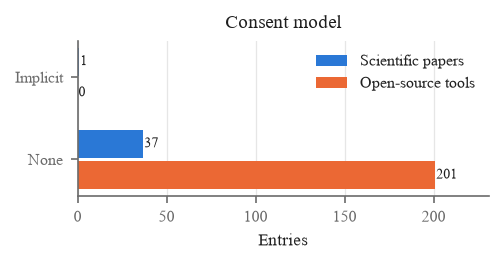

source_type    Non-Scientific  Scientific
consent_model                            
Implicit                    0           1
None                      201          37

Papers with any consent mechanism: 1/38  |  Tools: 0/201


In [12]:
# Consent model by source (counts)
t = df.groupby(['consent_model', 'source_type']).size().unstack(fill_value=0)
order_c = [c for c in ['Explicit', 'Implicit', 'None'] if c in t.index]
fig, ax = plt.subplots(figsize=(COL_W, 1.8))
grouped_barh(ax, t, order_c, xlabel='Entries', percent=False, label_fmt='{:.0f}')
ax.set_xlim(0, t.values.max() * 1.15); ax.legend(loc='upper right'); ax.set_title('Consent model')
fig.tight_layout(); savefig(fig, 'consent_model'); plt.show()
print(t.to_string())
print(f"\nPapers with any consent mechanism: {(sci['consent_model'] != 'None').sum()}/{len(sci)}  |  Tools: {(nons['consent_model'] != 'None').sum()}/{len(nons)}")

## 4. Data sensitivity and attacker behaviour - PAPER FIG 2

**Rubric (deployment-independent).** You mentioned whether sensitivity should depend on live deployment ("what if a simulation is deployed on the internet and they collect IP?"). It should not: sensitivity describes what the honeypot is built to collect, wherever it runs.
- **High** - collects credentials, personal or third-party data (e.g., subscriber data, real users' messages, nearby devices), or control-system commands / data (ICS, IIoT, satellite).
- **Medium** - collects attacker identifiers or session, traffic or malware data (IP addresses, commands, pcaps, payloads) but none of the above.
- **Low** - no identifiable data (synthetic or aggregate only, or nothing stated).

**Attacker behaviour** (commands, interaction sequences, TTPs) is reported separately, as asked in the meeting, because it describes what attackers did rather than how sensitive the data is.

The level and the collected categories are recorded at the start of each `data_sensitivity_justification` ("Rubric ...: High - collects credentials. Attacker behaviour captured: Yes.").

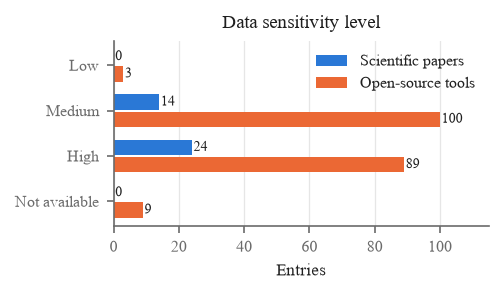

source_type       Non-Scientific  Scientific
data_sensitivity                            
Low                            3           0
Medium                       100          14
High                          89          24
Not available                  9           0


In [13]:
# Data sensitivity level by source (counts; original chart, new rubric values)
so = ['Low', 'Medium', 'High', 'Not available']
t = df.groupby(['data_sensitivity', 'source_type']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(COL_W, 2.0))
grouped_barh(ax, t, [x for x in so if x in t.index], xlabel='Entries', percent=False, label_fmt='{:.0f}')
ax.set_xlim(0, t.values.max() * 1.15); ax.legend(loc='upper right'); ax.set_title('Data sensitivity level')
fig.tight_layout(); savefig(fig, 'data_sensitivity'); plt.show()
print(t.reindex([x for x in so if x in t.index]).to_string())

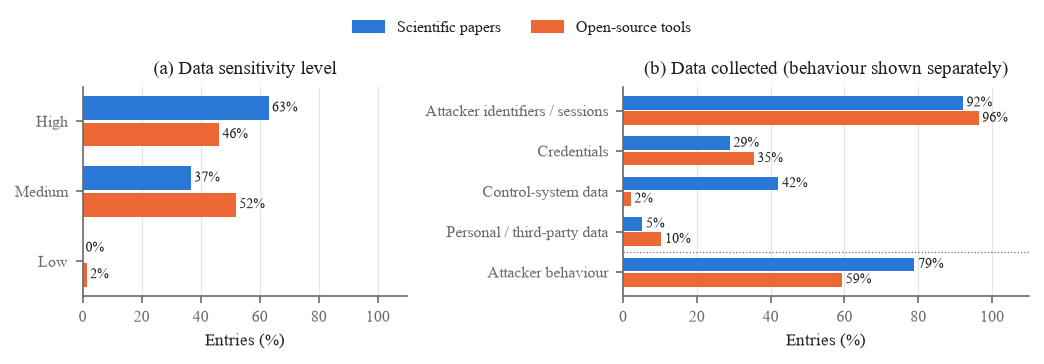

source_type       Non-Scientific  Scientific
data_sensitivity                            
High                          89          24
Medium                       100          14
Low                            3           0

                                 Scientific  Non-Scientific
Attacker identifiers / sessions        92.1            96.4
Credentials                            28.9            35.4
Control-system data                    42.1             2.1
Personal / third-party data             5.3            10.4
Attacker behaviour                     78.9            59.4


In [14]:
CATS = {'Credentials': 'credentials', 'Personal / third-party data': 'personal or third-party data',
        'Control-system data': 'control-system', 'Attacker identifiers / sessions': 'attacker identifiers'}
def rubric_flags(j):
    head = str(j).split('[Earlier value')[0].split('. Attacker behaviour')[0].lower()
    return {k: (v in head) for k, v in CATS.items()}
flags = pd.DataFrame(list(df['data_sensitivity_justification'].map(rubric_flags)), index=df.index)
flags['Attacker behaviour'] = df['data_sensitivity_justification'].str.contains('Attacker behaviour captured: Yes', na=False)
# identifiers are implied for High entries that collect them too; count Medium-level reason plus any entry logging IPs/sessions
flags['Attacker identifiers / sessions'] |= df['data_types_collected'].str.contains(r'\bIPs?\b|IP address|session|command|traffic|pcap|payload', case=False, na=False)
valid = df['data_sensitivity'] != 'Not available'

fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.4), gridspec_kw={'width_ratios': [1, 1.25]})
# (a) sensitivity level
lv = ['High', 'Medium', 'Low']
t = df[valid].groupby(['data_sensitivity', 'source_type']).size().unstack(fill_value=0)
tp = t.div(df[valid].groupby('source_type').size(), axis=1) * 100
grouped_barh(axes[0], tp, lv); axes[0].set_title('(a) Data sensitivity level')
# (b) what is collected, behaviour separated
cats = ['Attacker identifiers / sessions', 'Credentials', 'Control-system data', 'Personal / third-party data', 'Attacker behaviour']
fp = pd.DataFrame({src: {c: pct(flags.loc[valid & df['source_type'].eq(src), c]) for c in cats} for src in ['Scientific', 'Non-Scientific']})
grouped_barh(axes[1], fp, cats); axes[1].set_title('(b) Data collected (behaviour shown separately)')
axes[1].axhline(3.5, color=MUTED, lw=0.6, ls=':')
top_legend(fig); savefig(fig, 'paper_fig2_sensitivity'); plt.show()
print(t.reindex(lv).to_string()); print(); print(fp.round(1).to_string())

In [15]:
# Sensitivity vs deployment: the rubric no longer depends on where the honeypot runs
dep = sci['deployment'].str.replace(r'\s*\(.*', '', regex=True).map({'Yes': 'Internet-facing', 'No': 'Lab / simulation'})
print(pd.crosstab(dep, sci['data_sensitivity']).reindex(columns=['High', 'Medium', 'Low'], fill_value=0).to_string())

data_sensitivity  High  Medium  Low
deployment                         
Internet-facing     16       9    0
Lab / simulation     8       5    0


## 5. Containment and data sharing - PAPER FIG 3

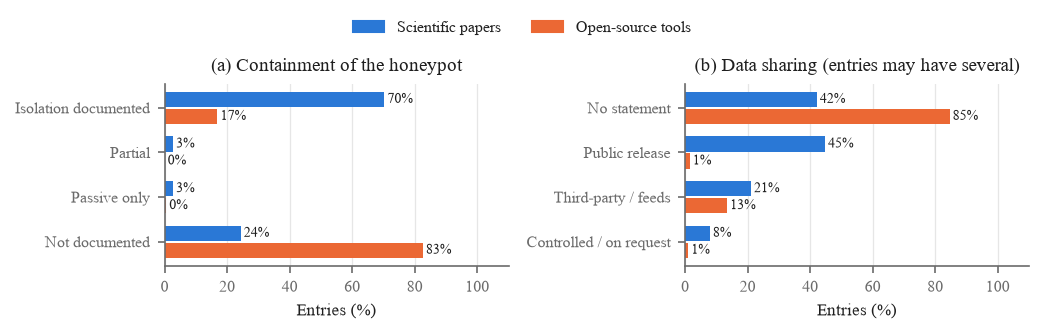

source_type           Non-Scientific  Scientific
containment_cat                                 
Isolation documented              34          26
Partial                            0           1
Passive only                       1           1
Not documented                   166           9

col_0                    Non-Scientific  Scientific
row_0                                              
No statement                        170          16
Public release                        3          17
Third-party / feeds                  27           8
Controlled / on request               2           3


In [16]:
def contain_cat(v):
    v = str(v).lower()
    if v.startswith(('not applicable', 'not available')): return None
    if v.startswith('not documented'): return 'Not documented'
    if v.startswith('passive'): return 'Passive only'
    if v.startswith('partial'): return 'Partial'
    return 'Isolation documented'
def share_cat(v):
    v = str(v).lower()
    if v.startswith(('none mentioned', 'not available', 'nan')): return 'No statement'
    out = []
    if re.search(r'public|open source|open-source|released', v): out.append('Public release')
    if re.search(r'third-party|virustotal|misp|dshield|hpfeeds|project honey pot|external|anomali|community', v): out.append('Third-party / feeds')
    if re.search(r'on request|request|controlled|management', v): out.append('Controlled / on request')
    return out or ['Other statement']
df['containment_cat'] = df['containment_measures'].map(contain_cat)
share = df['data_sharing'].map(share_cat).explode()

fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.2))
c_order = ['Isolation documented', 'Partial', 'Passive only', 'Not documented']
t = df.dropna(subset=['containment_cat']).groupby(['containment_cat', 'source_type']).size().unstack(fill_value=0)
grouped_barh(axes[0], t.div(df.dropna(subset=['containment_cat']).groupby('source_type').size(), axis=1) * 100, c_order)
axes[0].set_title('(a) Containment of the honeypot')
s_order = ['No statement', 'Public release', 'Third-party / feeds', 'Controlled / on request']
st = pd.crosstab(share.values, df.loc[share.index, 'source_type'].values)
grouped_barh(axes[1], st.div(pd.Series(N), axis=1) * 100, [o for o in s_order if o in st.index])
axes[1].set_title('(b) Data sharing (entries may have several)')
top_legend(fig); savefig(fig, 'paper_fig3_containment_sharing'); plt.show()
print(t.reindex(c_order).fillna(0).astype(int).to_string()); print(); print(st.reindex(s_order).fillna(0).astype(int).to_string())

In [17]:
# Internet-facing papers without documented containment (the cases behind Fig 3a)
live = sci[sci['deployment'].str.startswith('Yes', na=False)]
gap = live[live['containment_measures'].str.lower().str.startswith('not documented', na=False)]
print(f"Internet-facing papers: {len(live)} | with no containment described: {len(gap)}")
print(gap['identifier'].str.split(':').str[0].to_string(index=False))

Internet-facing papers: 25 | with no containment described: 9
                                          HoneyPLC
                                      LLM Honeypot
                                          HoneyGPT
Adversarial Reinforcement Learning Based IoT Ho...
                                            NeuPot
                                          HoneyCam
                                            ICSpot
                                            AIIPot
Analysis of ICS and SCADA Systems Attacks Using...


## 6. Data minimization, retention and deployment

source_type        Non-Scientific  Scientific
data_minimization                            
Not discussed                 197          34
Yes (Partial)                   4           4 

source_type         Non-Scientific  Scientific
deception_framing                             
Ethical discussion               0           1
Not available                    9           0
Purely technical               192          37 



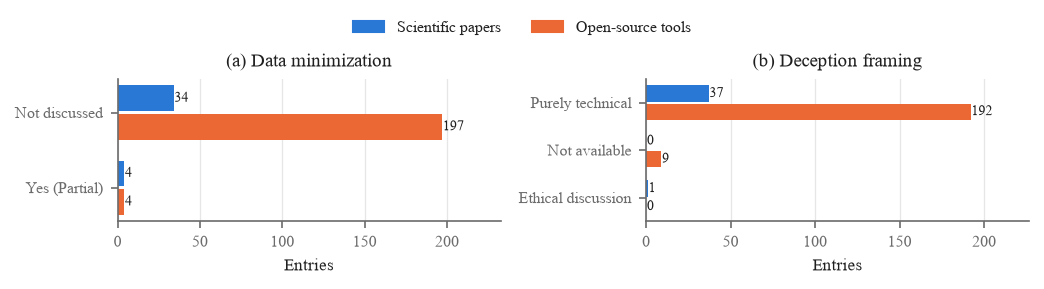

In [18]:
# Data minimization and deception framing (original charts)
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 1.9))
for ax, col, title in [(axes[0], 'data_minimization', '(a) Data minimization'), (axes[1], 'deception_framing', '(b) Deception framing')]:
    t = df.groupby([col, 'source_type']).size().unstack(fill_value=0)
    grouped_barh(ax, t, t.sum(axis=1).sort_values(ascending=False).index.tolist(), xlabel='Entries', percent=False, label_fmt='{:.0f}')
    ax.set_xlim(0, t.values.max() * 1.18); ax.set_title(title)
    print(t.to_string(), '\n')
top_legend(fig); savefig(fig, 'minimization_deception'); plt.show()

In [19]:
rows = {}
for src, sub in [('Scientific', sci), ('Non-Scientific', nons)]:
    rows[src] = {
        'Minimization (incl. partial)': pct(sub['data_minimization'].str.startswith('Yes', na=False)),
        'Retention policy': pct(documented(sub['data_retention_policy'], ['Not discussed', 'Not documented', 'Not available'])),
        'Internet-facing (actual or by design)': pct(sub['deployment'].str.contains('Internet-facing', na=False)),
    }
print(pd.DataFrame(rows).round(1).to_string())
print('\nDeployment (papers):'); print(sci['deployment'].value_counts().to_string())
print('\nMinimization statements:'); print(df[df['data_minimization'].str.startswith('Yes', na=False)][['source_type', 'identifier']].to_string(index=False))

                                       Scientific  Non-Scientific
Minimization (incl. partial)                 10.5             2.0
Retention policy                              0.0             0.0
Internet-facing (actual or by design)        65.8             5.0

Deployment (papers):
deployment
Yes (Internet-facing)    25
No (Controlled/lab)       9
No (Simulation only)      4

Minimization statements:
   source_type                                                              identifier
    Scientific                        The Case for Virtual PLC-enabled Honeypot Design
    Scientific TwinPot: Digital Twin-assisted Honeypot for Cyber-Secure Smart Seaports
    Scientific       Cellpot: A Concept for Next Generation Cellular Network Honeypots
    Scientific              Cyber-Physical Deception Through Coordinated IoT Honeypots
Non-Scientific                                                                   Helix
Non-Scientific                                                         

## 7. Open-source tools: documentation quantity - PAPER FIG 4 (candidate)

Documentation *quality* became documentation *quantity*. The level is now measured from the harvested documentation text (README + wiki + docs folder + external pages): None < 50 words, Minimal < 500, Moderate < 2,000, Extensive >= 2,000. A single long README can therefore be Extensive. Five tools whose external documentation could not be retrieved keep their earlier level.

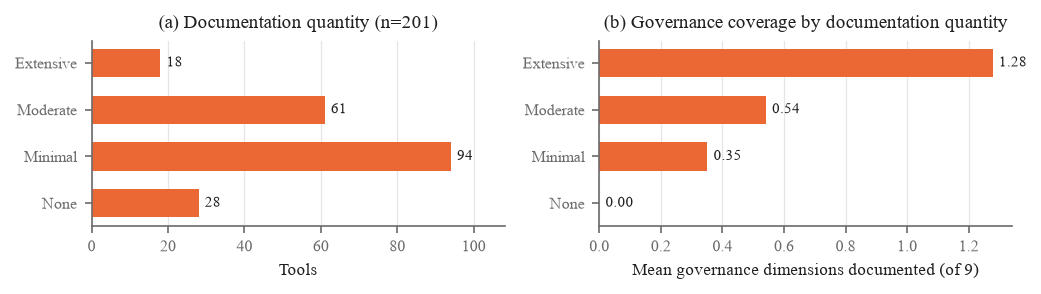

           tools  mean dimensions
doc_level                        
Extensive     18             1.28
Moderate      61             0.54
Minimal       94             0.35
None          28             0.00


In [20]:
d_order = ['Extensive', 'Moderate', 'Minimal', 'None']
dc = nons['doc_level'].value_counts().reindex(d_order).fillna(0).astype(int)
gov_tool = pd.DataFrame({k: f(nons) for k, f in DIMS.items()}).sum(axis=1)
mean_dims = gov_tool.groupby(nons['doc_level']).mean().reindex(d_order)

fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.0))
b = axes[0].barh(d_order, dc.values, color=TOOL, height=0.6); axes[0].invert_yaxis()
axes[0].bar_label(b, padding=3, fontsize=7); axes[0].set_xlabel('Tools'); axes[0].set_title('(a) Documentation quantity (n=201)')
axes[0].set_xlim(0, dc.max() * 1.15)
b = axes[1].barh(d_order, mean_dims.values, color=TOOL, height=0.6); axes[1].invert_yaxis()
axes[1].bar_label(b, fmt='%.2f', padding=3, fontsize=7); axes[1].set_xlabel(f'Mean governance dimensions documented (of {len(DIMS)})')
axes[1].set_title('(b) Governance coverage by documentation quantity')
fig.tight_layout(); savefig(fig, 'paper_fig4_documentation'); plt.show()
print(pd.DataFrame({'tools': dc, 'mean dimensions': mean_dims.round(2)}).to_string())

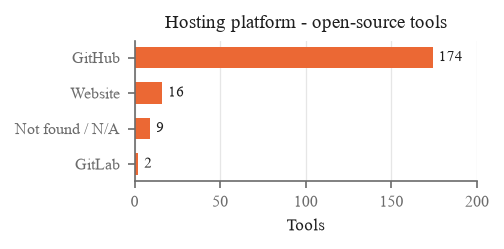

platform
GitHub             174
Website             16
Not found / N/A      9
GitLab               2


In [21]:
# Hosting platform (Irrelevant + Not Found combined, Meeting 12)
pc = nons['platform'].value_counts()
fig, ax = plt.subplots(figsize=(COL_W, 1.7))
b = ax.barh(pc.index, pc.values, color=TOOL, height=0.6); ax.invert_yaxis()
ax.bar_label(b, padding=3, fontsize=7); ax.set_xlim(0, pc.max() * 1.15); ax.set_xlabel('Tools')
ax.set_title('Hosting platform - open-source tools'); fig.tight_layout(); savefig(fig, 'platforms'); plt.show()
print(pc.to_string())

Tools with star data: 175 | median 48 | mean 358 | max 9300


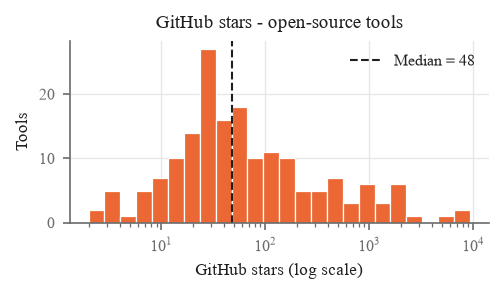

In [22]:
# GitHub stars distribution (log scale)
stars = nons['github_stars'].map(parse_stars); s_ = stars[stars > 0]
print(f"Tools with star data: {len(s_)} | median {s_.median():.0f} | mean {s_.mean():.0f} | max {s_.max():.0f}")
fig, ax = plt.subplots(figsize=(COL_W, 2.0))
bins = np.logspace(np.log10(max(s_.min(), 1)), np.log10(s_.max()), 25)
ax.hist(s_, bins=bins, color=TOOL, edgecolor='white', linewidth=0.6); ax.set_xscale('log')
ax.axvline(s_.median(), color=INK, ls='--', lw=1, label=f'Median = {s_.median():.0f}')
ax.grid(axis='y'); ax.set_xlabel('GitHub stars (log scale)'); ax.set_ylabel('Tools'); ax.legend(loc='upper right')
ax.set_title('GitHub stars - open-source tools'); fig.tight_layout(); savefig(fig, 'github_stars'); plt.show()

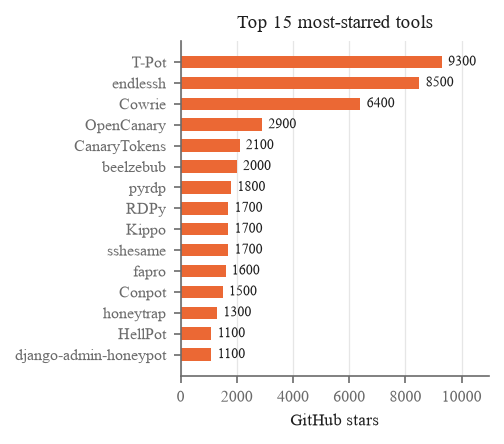

,identifier,stars,domain,interaction_level,doc_level,containment_measures
0,T-Pot,9300.0,IT,Low,Extensive,Not documented; containment gap noted
1,endlessh,8500.0,IT,Low,Moderate,Not documented
2,Cowrie,6400.0,IT,Medium,Extensive,Technical isolation (documented)
3,OpenCanary,2900.0,IT,Low,Extensive,Not documented
4,CanaryTokens,2100.0,IT,Low,Moderate,Not documented
5,beelzebub,2000.0,IT,Medium,Moderate,Technical isolation (documented); containment ...
6,pyrdp,1800.0,IT,High,Extensive,Not documented; MITM to real backend creates s...
7,RDPy,1700.0,IT,Medium,Moderate,Not documented
8,Kippo,1700.0,IT,Medium,Moderate,Technical isolation (documented); containment ...
9,sshesame,1700.0,IT,Low,Minimal,Technical isolation (documented)


In [23]:
# Top 15 most-starred tools
top15 = nons.assign(stars=stars).nlargest(15, 'stars')
fig, ax = plt.subplots(figsize=(COL_W, 3.0))
b = ax.barh(top15['identifier'], top15['stars'], color=TOOL, height=0.6); ax.invert_yaxis()
ax.bar_label(b, fmt='%.0f', padding=3, fontsize=6.5); ax.set_xlim(0, top15['stars'].max() * 1.18); ax.set_xlabel('GitHub stars')
ax.set_title('Top 15 most-starred tools'); fig.tight_layout(); savefig(fig, 'top15_stars'); plt.show()
display(top15[['identifier', 'stars', 'domain', 'interaction_level', 'doc_level', 'containment_measures']].reset_index(drop=True))

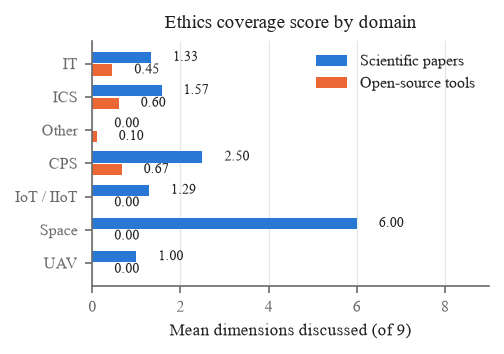

source_type   Non-Scientific  Scientific
domain_group                            
IT                      0.45        1.33
ICS                     0.60        1.57
Other                   0.10         NaN
CPS                     0.67        2.50
IoT / IIoT               NaN        1.29
Space                    NaN        6.00
UAV                      NaN        1.00


In [24]:
# Ethics coverage score by domain (original chart, now 9 dimensions), papers and tools
score = pd.DataFrame({k: f(df) for k, f in DIMS.items()}).sum(axis=1)
sbd = score.groupby([df['domain_group'], df['source_type']]).mean().unstack()
sbd = sbd.reindex(df['domain_group'].value_counts().index)
fig, ax = plt.subplots(figsize=(COL_W, 2.4))
grouped_barh(ax, sbd.fillna(0), xlabel=f'Mean dimensions discussed (of {len(DIMS)})', percent=False, label_fmt='{:.2f}')
ax.set_xlim(0, len(DIMS)); ax.legend(loc='upper right'); ax.set_title('Ethics coverage score by domain')
fig.tight_layout(); savefig(fig, 'ethics_by_domain'); plt.show()
print(sbd.round(2).to_string())

## 8. Interaction level vs data sensitivity

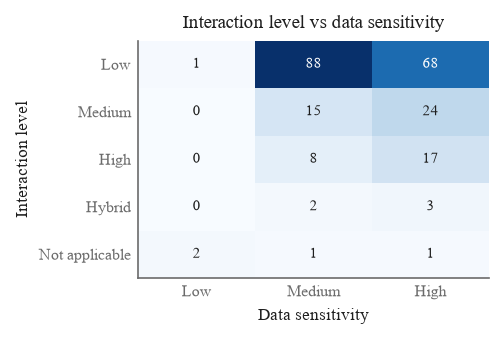

In [25]:
lv = ['Low', 'Medium', 'High', 'Hybrid', 'Not applicable']
ct = pd.crosstab(df['interaction_level'], df['data_sensitivity']).reindex(index=lv, columns=['Low', 'Medium', 'High']).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(COL_W, 2.3))
im = ax.imshow(ct.values, cmap='Blues', aspect='auto'); ax.grid(False); ax.tick_params(length=0)
ax.set_xticks(range(3)); ax.set_xticklabels(ct.columns); ax.set_yticks(range(len(lv))); ax.set_yticklabels(lv)
for (i, j), v in np.ndenumerate(ct.values):
    ax.text(j, i, v, ha='center', va='center', fontsize=7, color='white' if v > ct.values.max() * 0.55 else INK)
ax.set_xlabel('Data sensitivity'); ax.set_ylabel('Interaction level'); ax.set_title('Interaction level vs data sensitivity')
fig.tight_layout(); savefig(fig, 'interaction_vs_sensitivity'); plt.show()

## 9. Non-IT domains (ICS, CPS, IoT / IIoT, Space, UAV)

Non-IT entries: 37 | papers 29 | tools 8


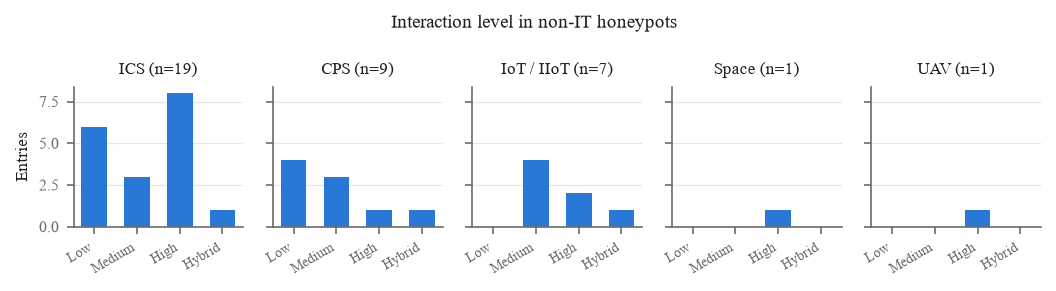

              entries  high_sensitivity  irb  containment_documented
domain_group                                                        
CPS                 9                 3    1                       6
ICS                19                18    0                      12
IoT / IIoT          7                 4    0                       5
Space               1                 1    1                       1
UAV                 1                 0    0                       1


In [26]:
nonit = df[~df['domain'].isin(['IT', 'Other', 'Not available'])]
print(f"Non-IT entries: {len(nonit)} | papers {(nonit['source_type'] == 'Scientific').sum()} | tools {(nonit['source_type'] == 'Non-Scientific').sum()}")
lv_order = ['Low', 'Medium', 'High', 'Hybrid']
doms = nonit['domain_group'].value_counts().index.tolist()
fig, axes = plt.subplots(1, len(doms), figsize=(FULL_W, 1.9), sharey=True)
for ax, d in zip(axes, doms):
    ic = nonit[nonit['domain_group'] == d]['interaction_level'].value_counts().reindex(lv_order).fillna(0)
    ax.bar(range(len(lv_order)), ic.values, color=SCI, width=0.6); ax.set_xticks(range(len(lv_order)))
    ax.set_xticklabels(lv_order, rotation=30, ha='right', fontsize=6.5); ax.grid(axis='y'); ax.grid(axis='x', visible=False)
    ax.set_title(f'{d} (n={int((nonit["domain_group"] == d).sum())})', fontsize=8)
axes[0].set_ylabel('Entries'); fig.suptitle('Interaction level in non-IT honeypots', fontsize=9)
fig.tight_layout(); savefig(fig, 'nonit_interaction'); plt.show()
summary = nonit.groupby('domain_group').agg(
    entries=('identifier', 'size'),
    high_sensitivity=('data_sensitivity', lambda s: (s == 'High').sum()),
    irb=('irb_mentioned', lambda s: (s == 'Yes').sum()),
    containment_documented=('containment_measures', lambda s: (~s.str.lower().str.startswith(('not documented', 'not applicable'), na=True)).sum()),
)
print(summary.to_string())

## 10. Summary table and five key results for the paper

In [27]:
def row(sub):
    return {'N': len(sub),
            'IRB (%)': pct(sub['irb_mentioned'].eq('Yes')),
            'Consent (%)': pct(sub['consent_model'].isin(['Explicit', 'Implicit'])),
            'Minimization (%)': pct(sub['data_minimization'].str.startswith('Yes', na=False)),
            'Responsibility explicit (%)': pct(sub['researcher_responsibility'].eq('Explicit')),
            'Containment documented (%)': pct(DIMS['Containment documented'](sub)),
            'High sensitivity (%)': pct(sub['data_sensitivity'].eq('High'))}
tab = pd.DataFrame({'Scientific papers': row(sci), 'Open-source tools': row(nons), 'All': row(df)}).T
display(tab.round(1))

,N,IRB (%),Consent (%),Minimization (%),Responsibility explicit (%),Containment documented (%),High sensitivity (%)
Scientific papers,38.0,5.3,2.6,10.5,15.8,73.7,63.2
Open-source tools,201.0,0.0,0.0,2.0,9.5,17.4,44.3
All,239.0,0.8,0.4,3.3,10.5,26.4,47.3


In [28]:
# Key findings (original printout, updated values)
print('=' * 60); print('KEY FINDINGS - HONEYPOT ETHICS LITERATURE REVIEW'); print('=' * 60)
print(f"Entries: {len(df)} | scientific papers: {len(sci)} | open-source tools: {len(nons)}")
for name, f in [('IRB approval', lambda d: d['irb_mentioned'].eq('Yes')),
                ('Consent (explicit/implicit)', lambda d: d['consent_model'].isin(['Explicit', 'Implicit'])),
                ('High data sensitivity', lambda d: d['data_sensitivity'].eq('High')),
                ('Deception ethics discussed', lambda d: d['deception_framing'].eq('Ethical discussion'))]:
    print(f"{name:30s} papers {f(sci).sum():3d}/{len(sci)} ({pct(f(sci)):5.1f}%) | tools {f(nons).sum():3d}/{len(nons)} ({pct(f(nons)):5.1f}%)")
print('\nDomain distribution:'); print(df['domain'].value_counts().to_string())
print('\nInteraction levels:'); print(df['interaction_level'].value_counts().to_string())

KEY FINDINGS - HONEYPOT ETHICS LITERATURE REVIEW
Entries: 239 | scientific papers: 38 | open-source tools: 201
IRB approval                   papers   2/38 (  5.3%) | tools   0/201 (  0.0%)
Consent (explicit/implicit)    papers   1/38 (  2.6%) | tools   0/201 (  0.0%)
High data sensitivity          papers  24/38 ( 63.2%) | tools  89/201 ( 44.3%)
Deception ethics discussed     papers   1/38 (  2.6%) | tools   0/201 (  0.0%)

Domain distribution:
domain
IT                       192
ICS                       19
Other                     10
CPS                        9
IoT                        6
Industrial IoT (IIoT)      1
Space                      1
UAV                        1

Interaction levels:
interaction_level
Low               157
Medium             39
High               25
Not available       9
Hybrid              5
Not applicable      4


In [29]:
live = sci[sci['deployment'].str.startswith('Yes', na=False)]
live_nocont = live['containment_measures'].str.lower().str.startswith('not documented', na=False).sum()
hs = sci['data_sensitivity'].eq('High')
tp_tools = nons['data_sharing'].str.contains('Third-party|third-party|HPFeeds|DShield|Anomali|external', na=False)
print('FIVE KEY RESULTS')
print('-' * 60)
print(f"1. Oversight is rare: {sci['irb_mentioned'].eq('Yes').sum()}/{len(sci)} papers report IRB approval and "
      f"{(sci['consent_model'] != 'None').sum()}/{len(sci)} uses any consent mechanism (a warning banner); no tool documents either.")
print(f"2. The data is sensitive: {hs.sum()}/{len(sci)} papers ({pct(hs):.0f}%) collect credentials, personal data or control-system data, "
      f"yet only {sci['data_minimization'].str.startswith('Yes', na=False).sum()} state any minimization and none states a retention policy.")
print(f"3. Containment is under-reported: {live_nocont}/{len(live)} Internet-facing papers describe no isolation or egress control.")
print(f"4. Responsibility is rarely explicit: {sci['researcher_responsibility'].eq('Explicit').sum()}/{len(sci)} papers and "
      f"{nons['researcher_responsibility'].eq('Explicit').sum()}/{len(nons)} tools state researcher or operator responsibility; "
      f"deception is discussed ethically in {sci['deception_framing'].eq('Ethical discussion').sum()}/{len(sci)} papers.")
print(f"5. Tools pass data beyond the operator: {tp_tools.sum()} tools document sharing with third parties or community feeds (some by default), and "
      f"{(nons['doc_level'].isin(['None', 'Minimal'])).sum()}/{len(nons)} have minimal or no documentation at all.")

FIVE KEY RESULTS
------------------------------------------------------------
1. Oversight is rare: 2/38 papers report IRB approval and 1/38 uses any consent mechanism (a warning banner); no tool documents either.
2. The data is sensitive: 24/38 papers (63%) collect credentials, personal data or control-system data, yet only 4 state any minimization and none states a retention policy.
3. Containment is under-reported: 9/25 Internet-facing papers describe no isolation or egress control.
4. Responsibility is rarely explicit: 6/38 papers and 19/201 tools state researcher or operator responsibility; deception is discussed ethically in 1/38 papers.
5. Tools pass data beyond the operator: 27 tools document sharing with third parties or community feeds (some by default), and 122/201 have minimal or no documentation at all.
